Import Libraries

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import RandomizedSearchCV
from sklearn.neural_network import MLPClassifier
from scipy import stats


Load and Preprocessed data

In [8]:

# Load the dataset with correct delimiter
file_path = r"PortScan.pcap_ISCX.csv"
data = pd.read_csv(file_path, delimiter=',')  # or simply pd.read_csv(file_path)

# Strip column names of any whitespace
data.columns = data.columns.str.strip()

# Handle missing values
data = data.dropna()

# Display dataset information
class_counts = data['Label'].value_counts()
class_percentages = data['Label'].value_counts(normalize=True) * 100
num_observations = data.shape[0]
num_attributes = data.shape[1]

# Print results
print("\nClass Distribution:\n", class_counts)
print("\nClass Percentages:\n", class_percentages)
print("\nNumber of observations: ", num_observations)
print("\nNumber of attributes: ", num_attributes)
print("\nCleaned Column Names:\n", data.columns.tolist())




Class Distribution:
 Label
PortScan    158930
BENIGN      127522
Name: count, dtype: int64

Class Percentages:
 Label
PortScan    55.482245
BENIGN      44.517755
Name: proportion, dtype: float64

Number of observations:  286452

Number of attributes:  79

Cleaned Column Names:
 ['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd P

Plot Correlation Heatmap

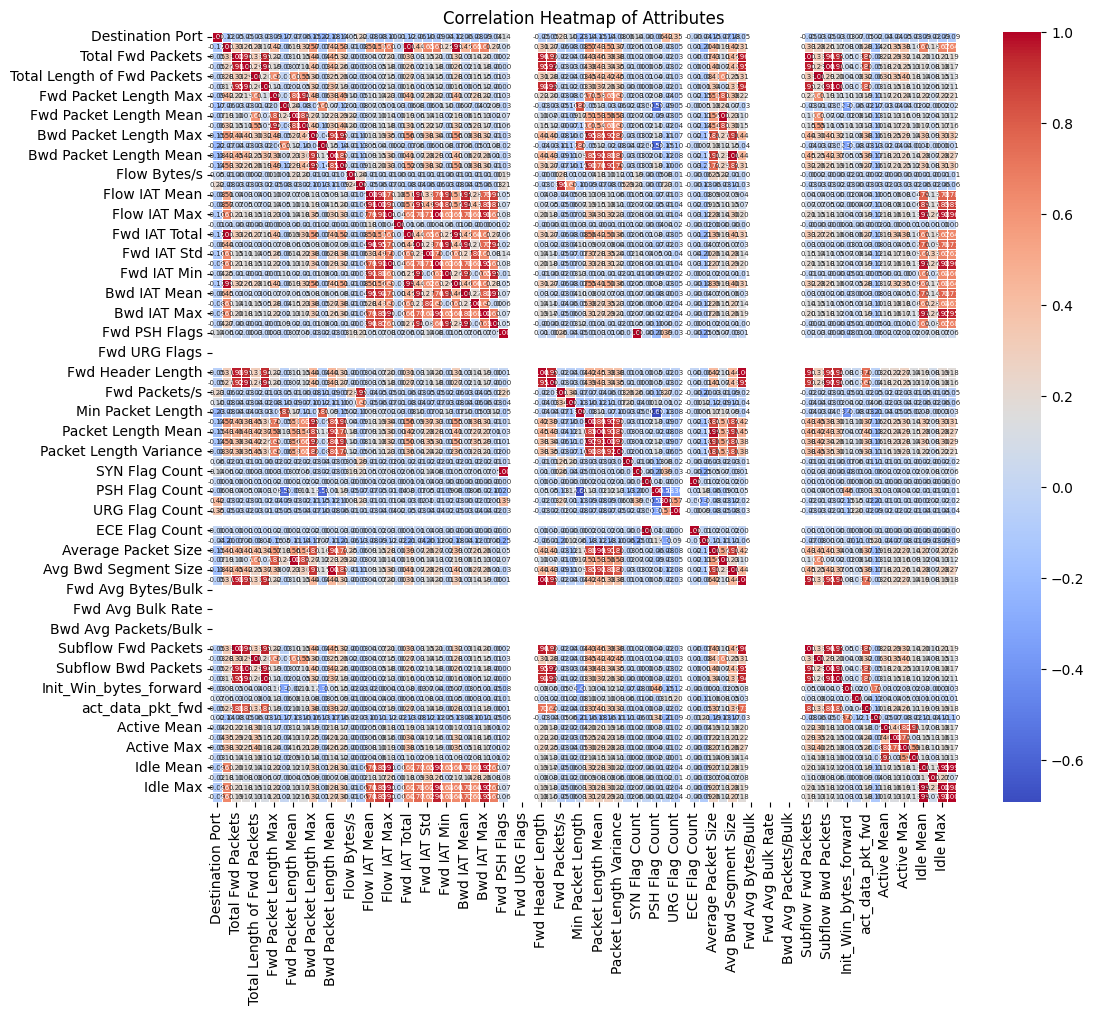

In [10]:
# Select only numeric columns for correlation calculation
numeric_data = data.select_dtypes(include=[np.number])

# Calculate and plot the correlation matrix
correlation_matrix = numeric_data.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, annot_kws={"size": 5}, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Attributes")
plt.show()